Import required libraries

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

import joblib

In [78]:
from pathlib import Path
import matplotlib.pyplot as plt

output_dir = Path(
    r"C:\Users\U S E R\Desktop\ML Assigment\project\output"
)

def save_plot(filename):
    plt.savefig(
        output_dir / filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )
    plt.show()
    plt.close()

In [79]:
dataset_path = r"C:\Users\U S E R\Desktop\ML Assigment\project\data\raw\student-mat.csv"

df = pd.read_csv(dataset_path, sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Understand the dataset

In [80]:
print("Column names:")
print(df.columns.tolist())

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [81]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    

In [82]:
display(df.describe())

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [83]:
print("\nCategorical features:")
display(df.select_dtypes(include="object").describe())


Categorical features:


,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
count,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395
unique,2,2,2,2,2,5,5,4,3,2,2,2,2,2,2,2,2
top,GP,F,U,GT3,T,other,other,course,mother,no,yes,no,yes,yes,yes,yes,no
freq,349,208,307,281,354,141,217,145,273,344,242,214,201,314,375,329,263


Check missing values

In [84]:
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total missing values: 0


Check duplicate records

In [85]:
duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


Validate important feature ranges

In [86]:
valid_ranges = {
    "age": (15, 22),
    "G1": (0, 20),
    "G2": (0, 20),
    "G3": (0, 20),
    "studytime": (1, 4),
    "failures": (0, 3),
    "Medu": (0, 4),
    "Fedu": (0, 4),
    "Dalc": (1, 5),
    "Walc": (1, 5),
    "health": (1, 5)
}

for column, (minimum, maximum) in valid_ranges.items():
    invalid = ~df[column].between(minimum, maximum)
    print(f"{column}: {invalid.sum()} invalid values")

print("Negative absences:", (df["absences"] < 0).sum())

age: 0 invalid values
G1: 0 invalid values
G2: 0 invalid values
G3: 0 invalid values
studytime: 0 invalid values
failures: 0 invalid values
Medu: 0 invalid values
Fedu: 0 invalid values
Dalc: 0 invalid values
Walc: 0 invalid values
health: 0 invalid values
Negative absences: 0


G3 grade distribution

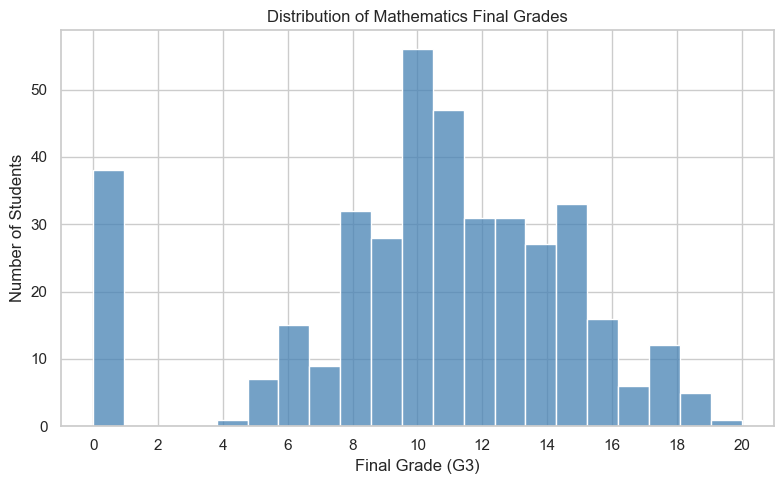

In [87]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["G3"],
    bins=21,
    kde=False,
    color="steelblue"
)

plt.title("Distribution of Mathematics Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.xticks(range(0, 21, 2))
plt.tight_layout()

# Save graph and display it
save_plot("07_G3_grade_distribution.png")

Relationship between G1, G2 and G3

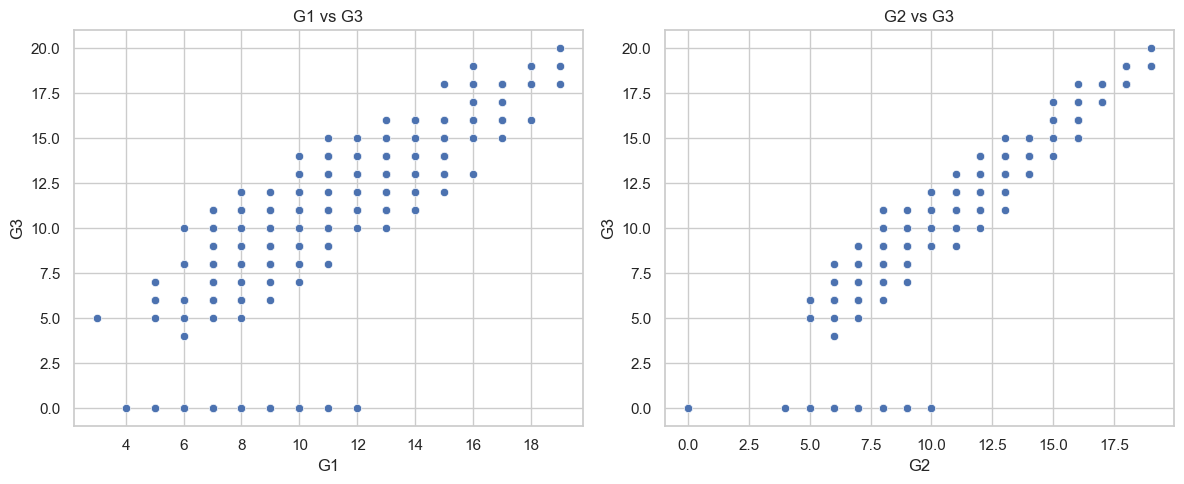

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=df, x="G1", y="G3", ax=axes[0])
axes[0].set_title("G1 vs G3")

sns.scatterplot(data=df, x="G2", y="G3", ax=axes[1])
axes[1].set_title("G2 vs G3")

plt.tight_layout()

save_plot("G1_G2_vs_G3_scatter.png")

Study time vs G3

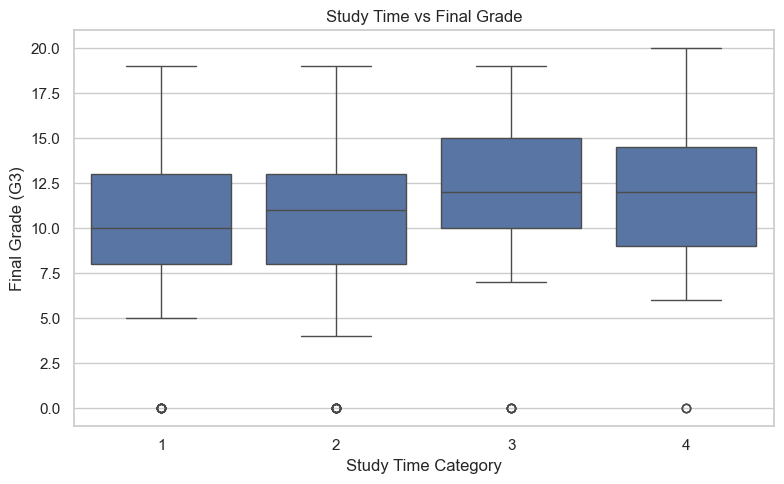

In [89]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="studytime", y="G3")

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade (G3)")

plt.tight_layout()

save_plot("Study_Time_vs_Final_Grade.png")

Correlation heatmap

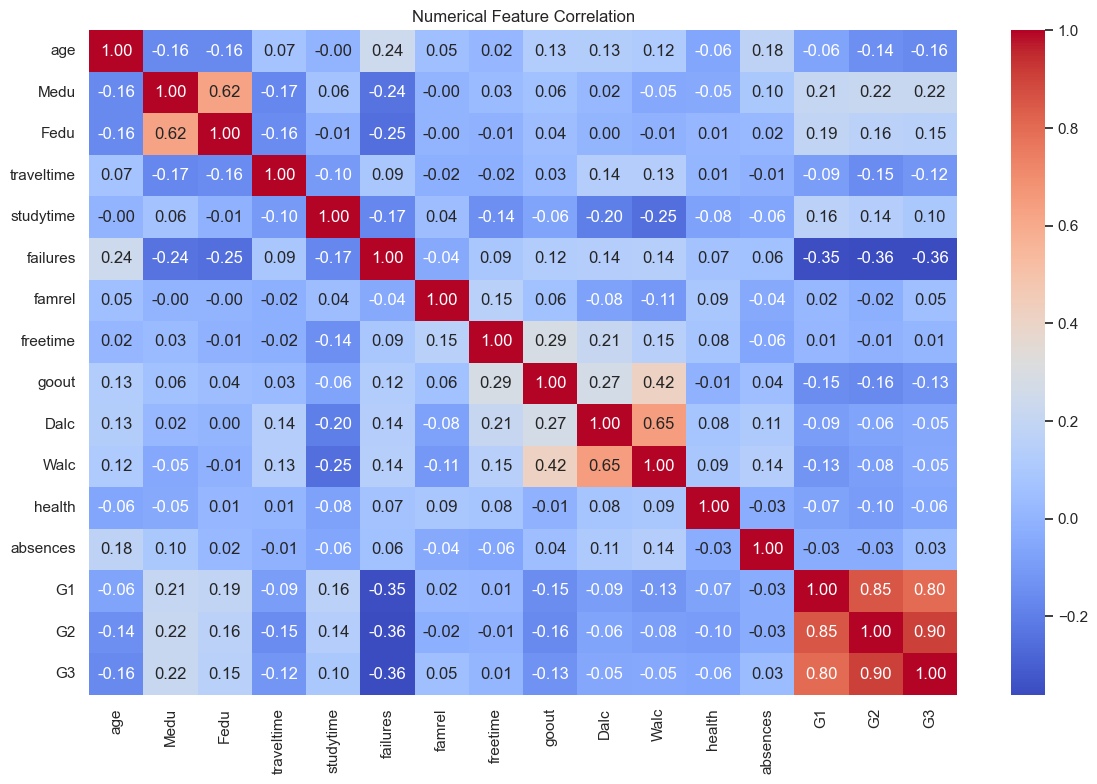

In [90]:
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation")

plt.tight_layout()

save_plot("Numerical_Feature_Correlation.png")

Separate features (X) and target (y)

In [91]:
X = df.drop(columns=["G3"])
y = df["G3"]

print("Input features:", X.shape)
print("Target:", y.shape)

print("\nInput columns:")
print(X.columns.tolist())

Input features: (395, 32)
Target: (395,)

Input columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


Split training and testing data

In [92]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (316, 32)
X_test: (79, 32)
y_train: (316,)
y_test: (79,)


Identify numerical and categorical columns

In [93]:
numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numerical_cols)
print("\nCategorical features:", categorical_cols)

print("\nNumerical count:", len(numerical_cols))
print("Categorical count:", len(categorical_cols))

Numerical features: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Categorical features: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Numerical count: 15
Categorical count: 17


Outlier Detection and Analysis

In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

outlier_results = []

for col in numerical_cols:
    data = X_train[col].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[(data < lower) | (data > upper)]

    outlier_results.append({
        "Feature": col,
        "Outlier Count": len(outliers),
        "Outlier Percentage": len(outliers) / len(data) * 100,
        "Lower Bound": lower,
        "Upper Bound": upper
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df = outlier_df.sort_values(
    "Outlier Count",
    ascending=False
).reset_index(drop=True)

display(outlier_df.round(2))

,Feature,Outlier Count,Outlier Percentage,Lower Bound,Upper Bound
0,failures,69,21.84,0.0,0.0
1,studytime,21,6.65,-0.5,3.5
2,famrel,20,6.33,2.5,6.5
3,freetime,18,5.70,1.5,5.5
4,Dalc,15,4.75,-0.5,3.5
5,absences,14,4.43,-12.0,20.0
6,G2,12,3.80,3.0,19.0
7,traveltime,6,1.90,-0.5,3.5
8,age,1,0.32,13.0,21.0
9,Fedu,1,0.32,0.5,4.5


Create a separate boxplot for each numerical feature

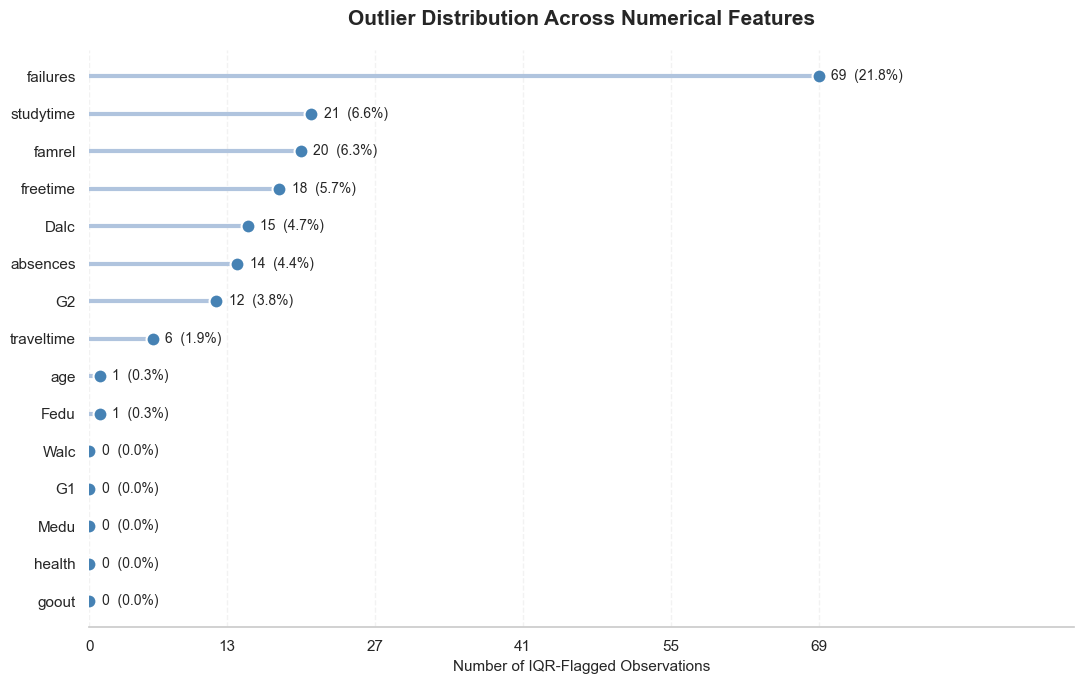

In [95]:
import matplotlib.pyplot as plt
import numpy as np

# Sort features by outlier count
plot_df = outlier_df.sort_values(
    "Outlier Count",
    ascending=True
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 7))

y_positions = np.arange(len(plot_df))
counts = plot_df["Outlier Count"].to_numpy()
percentages = plot_df["Outlier Percentage"].to_numpy()

# Draw horizontal lines
ax.hlines(
    y=y_positions,
    xmin=0,
    xmax=counts,
    color="lightsteelblue",
    linewidth=3
)

# Draw points
ax.scatter(
    counts,
    y_positions,
    s=100,
    color="steelblue",
    edgecolors="white",
    linewidths=1.5,
    zorder=3
)

# Display count and percentage labels
for i, (count, percentage) in enumerate(
    zip(counts, percentages)
):
    ax.annotate(
        f"{count}  ({percentage:.1f}%)",
        xy=(count, i),
        xytext=(9, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
        fontweight="medium"
    )

ax.set_yticks(y_positions)
ax.set_yticklabels(plot_df["Feature"], fontsize=11)

ax.set_xlabel("Number of IQR-Flagged Observations", fontsize=11)
ax.set_ylabel("")

ax.set_title(
    "Outlier Distribution Across Numerical Features",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlim(0, max(counts.max() * 1.35, 1))
ax.set_xticks(
    np.linspace(0, max(counts.max(), 1), 6).astype(int)
)

ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.grid(axis="y", visible=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()

save_plot("Outlier_Count_Comparison.png")

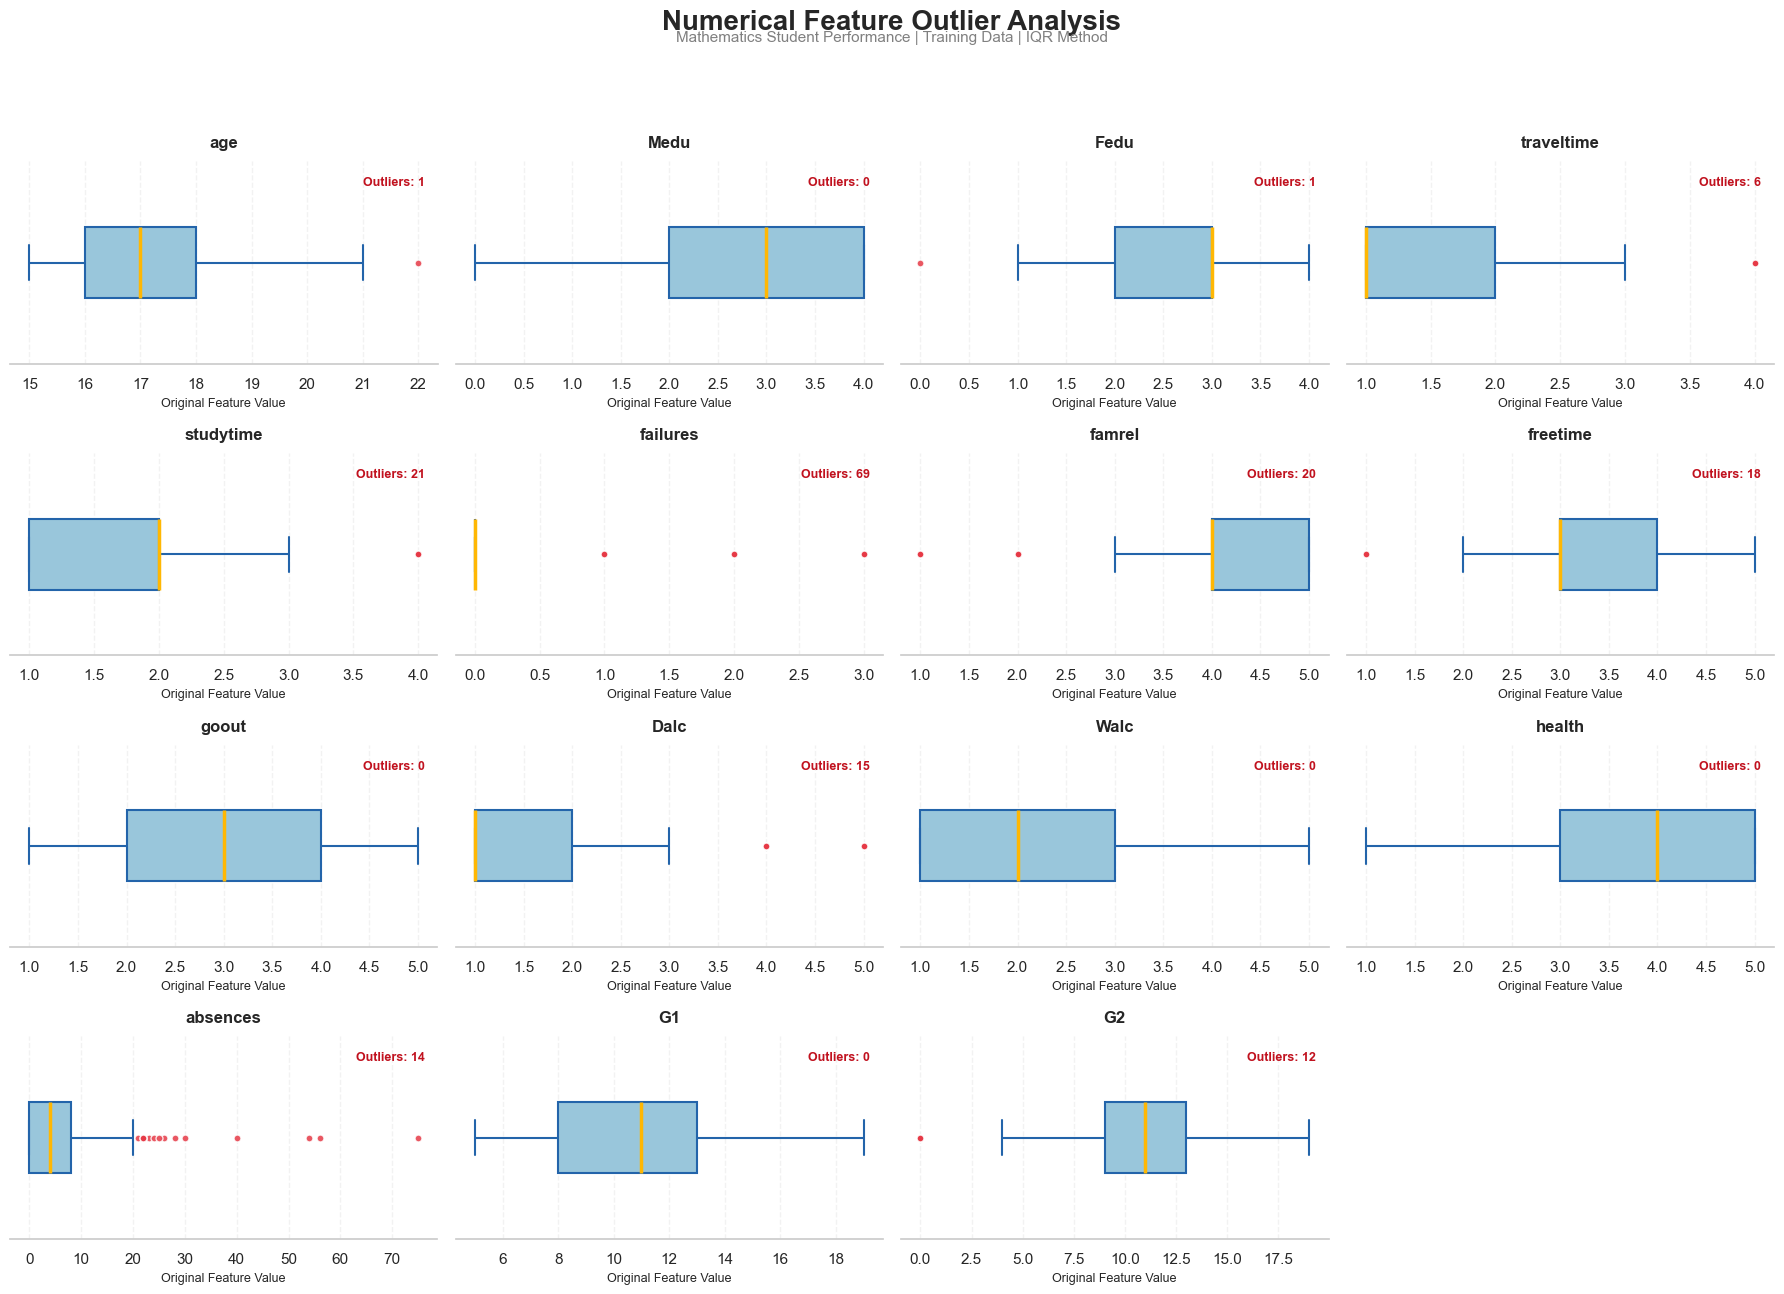

In [96]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math

# Plot settings
sns.set_theme(style="whitegrid")

n_cols = 4
n_rows = math.ceil(len(numerical_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, n_rows * 3.2)
)

axes = np.array(axes).flatten()

# Draw separate boxplots
for i, col in enumerate(numerical_cols):

    ax = axes[i]
    data = X_train[col].dropna()

    sns.boxplot(
        x=data,
        ax=ax,
        color="#8ECAE6",
        width=0.35,
        linewidth=1.5,
        boxprops={"edgecolor": "#2364AA"},
        medianprops={
            "color": "#FFB703",
            "linewidth": 2.5
        },
        whiskerprops={"color": "#2364AA"},
        capprops={"color": "#2364AA"},
        flierprops={
            "marker": "o",
            "markerfacecolor": "#E63946",
            "markeredgecolor": "white",
            "markersize": 5,
            "alpha": 0.85
        }
    )

    # Count IQR outliers
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_count = (
        (data < lower) | (data > upper)
    ).sum()

    ax.set_title(
        f"{col}",
        fontsize=12,
        fontweight="bold",
        pad=10
    )

    ax.set_xlabel("Original Feature Value", fontsize=9)
    ax.set_ylabel("")

    ax.text(
        0.97, 0.88,
        f"Outliers: {outlier_count}",
        transform=ax.transAxes,
        ha="right",
        fontsize=9,
        color="#C1121F",
        fontweight="bold"
    )

    ax.grid(axis="x", linestyle="--", alpha=0.25)
    ax.grid(axis="y", visible=False)

    sns.despine(ax=ax, left=True)

# Remove unused subplot panels
for j in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Numerical Feature Outlier Analysis",
    fontsize=20,
    fontweight="bold",
    y=1.01
)

fig.text(
    0.5,
    0.985,
    "Mathematics Student Performance | Training Data | IQR Method",
    ha="center",
    fontsize=11,
    color="gray"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save all boxplots in ONE PNG
save_plot("All_Numerical_Features_Outlier_Boxplots.png")

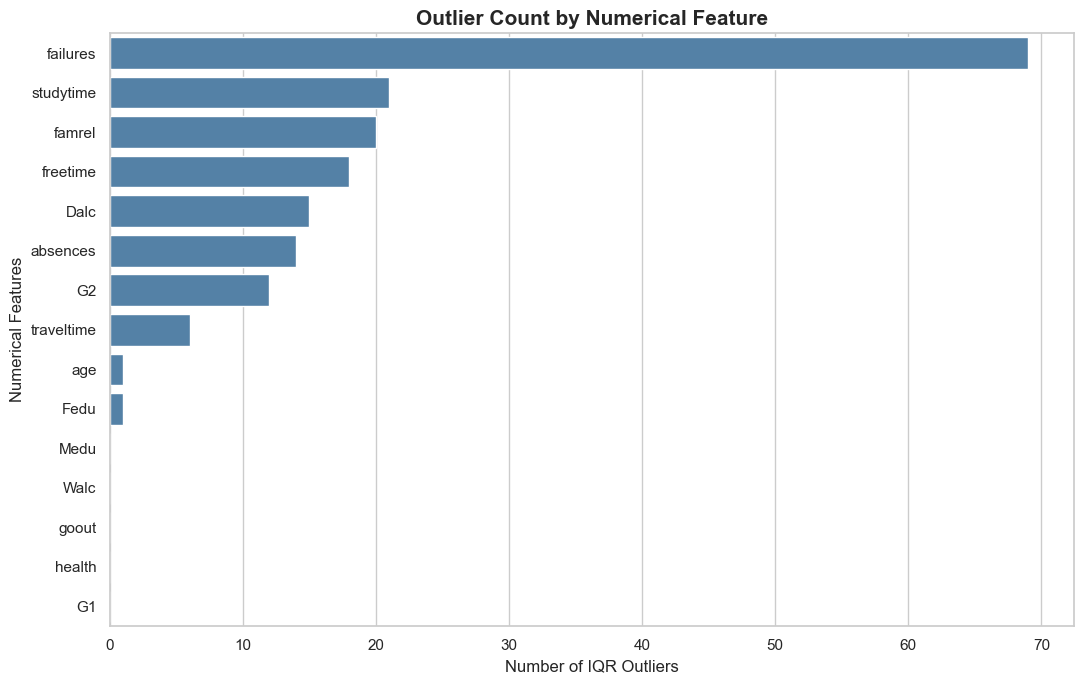

In [97]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=outlier_df,
    y="Feature",
    x="Outlier Count",
    color="steelblue"
)

plt.title(
    "Outlier Count by Numerical Feature",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of IQR Outliers")
plt.ylabel("Numerical Features")

plt.tight_layout()
save_plot("Outlier_Count_Comparison.png")

Create numerical preprocessing pipeline

In [98]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

print("Numerical pipeline created successfully!")

Numerical pipeline created successfully!


Visualize numerical features before scaling

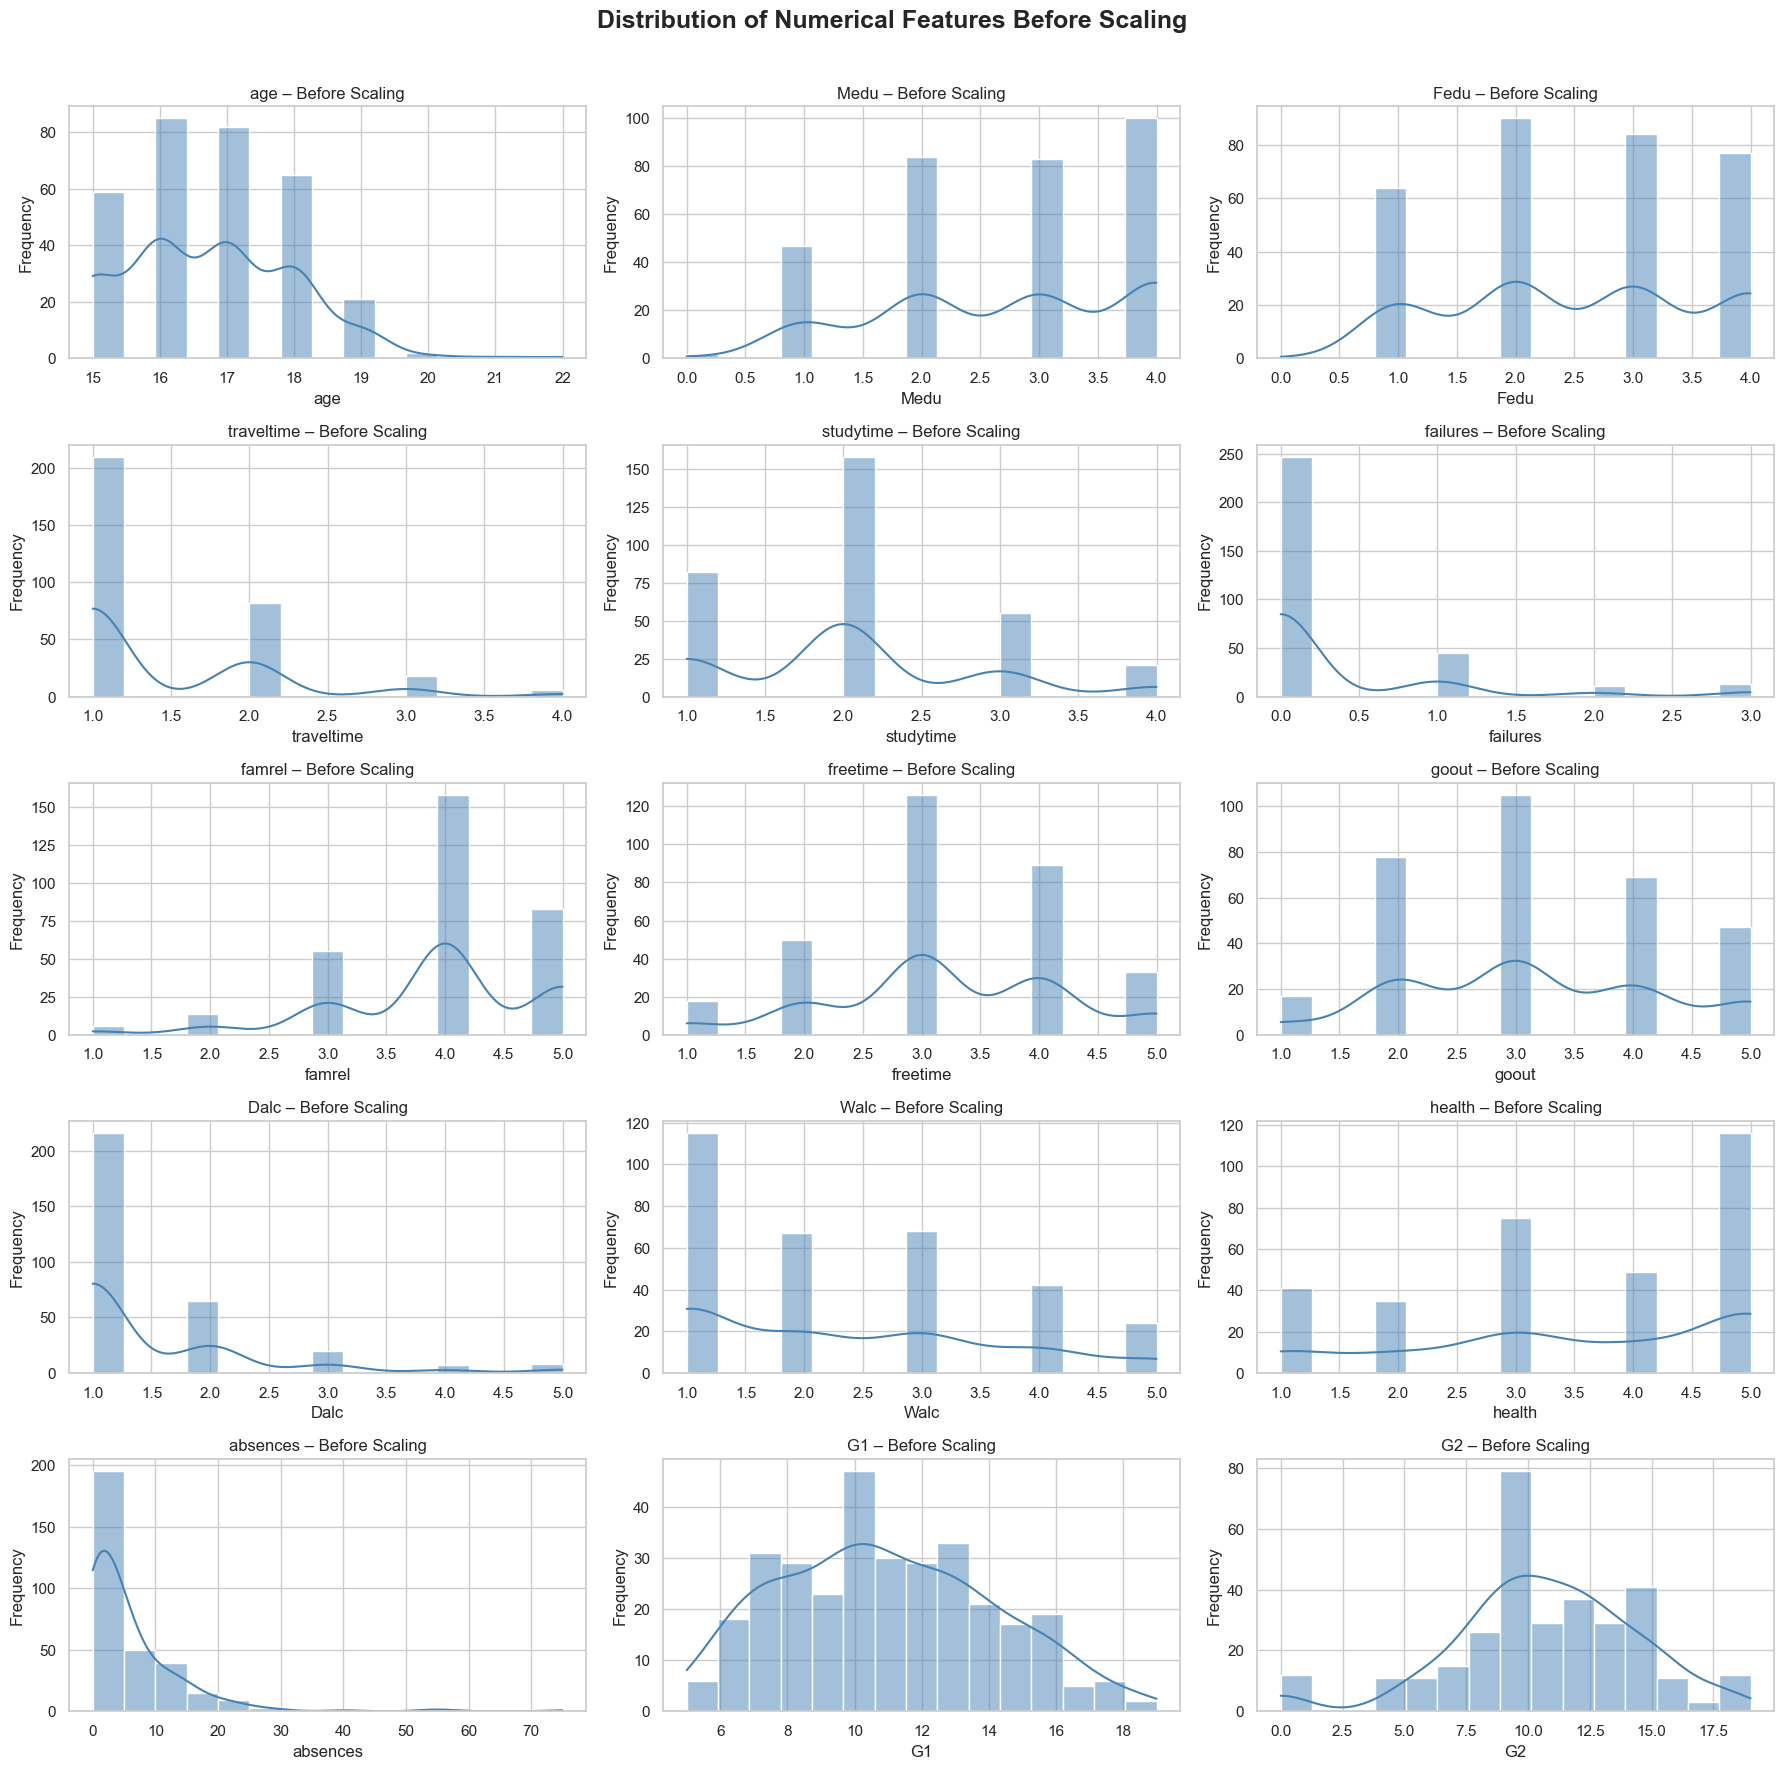

In [99]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_cols = 3
n_rows = math.ceil(len(numerical_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, n_rows * 3.5)
)

axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(
        X_train[col],
        bins=15,
        kde=True,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"{col} – Before Scaling")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

for j in range(len(numerical_cols), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Distribution of Numerical Features Before Scaling",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

save_plot("Numerical_Features_Before_Scaling.png")

Fit numerical preprocessing on training data

In [100]:
X_num_scaled = numerical_pipeline.fit_transform(
    X_train[numerical_cols]
)

X_num_scaled_df = pd.DataFrame(
    X_num_scaled,
    columns=numerical_cols,
    index=X_train.index
)

display(X_num_scaled_df.head())

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2
181,-0.5,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0,0.0,0.0,-0.5,-0.25,0.2,0.50
194,-0.5,-0.5,0.0,1.0,-1.0,0.0,1.0,0.0,0.0,0.0,-0.5,-0.5,-0.50,0.4,0.75
173,-0.5,-1.0,0.0,0.0,0.0,3.0,0.0,0.0,1.0,0.0,-0.5,-0.5,-0.50,-0.6,-1.00
63,-0.5,0.5,0.0,0.0,1.0,0.0,-1.0,1.0,0.5,1.0,1.0,0.0,-0.25,-0.2,-0.50
253,-0.5,-0.5,-2.0,1.0,-1.0,0.0,-1.0,0.0,-0.5,0.0,0.5,-0.5,-0.50,-0.6,-0.50


Visualize before and after scaling

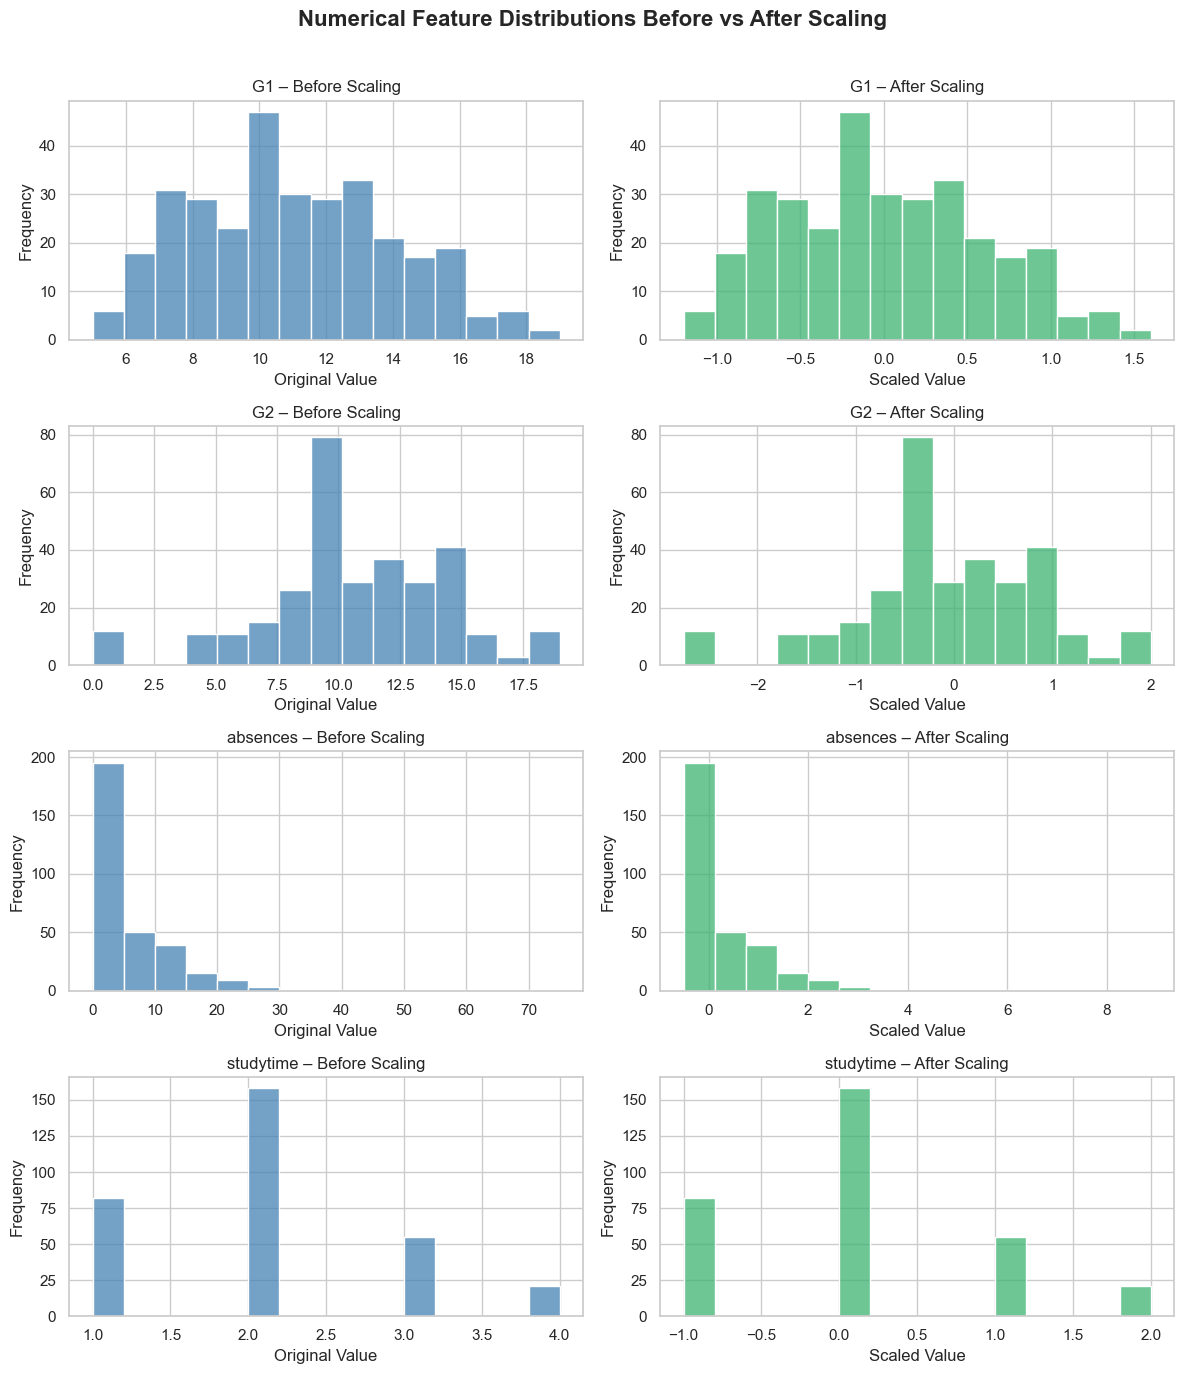

In [101]:
features_to_compare = ["G1", "G2", "absences", "studytime"]

fig, axes = plt.subplots(
    len(features_to_compare), 2,
    figsize=(12, 14)
)

for i, col in enumerate(features_to_compare):

    # Before Scaling
    sns.histplot(
        X_train[col],
        bins=15,
        ax=axes[i, 0],
        color="steelblue"
    )

    axes[i, 0].set_title(f"{col} – Before Scaling")
    axes[i, 0].set_xlabel("Original Value")
    axes[i, 0].set_ylabel("Frequency")

    # After Scaling
    sns.histplot(
        X_num_scaled_df[col],
        bins=15,
        ax=axes[i, 1],
        color="mediumseagreen"
    )

    axes[i, 1].set_title(f"{col} – After Scaling")
    axes[i, 1].set_xlabel("Scaled Value")
    axes[i, 1].set_ylabel("Frequency")

plt.suptitle(
    "Numerical Feature Distributions Before vs After Scaling",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

save_plot("Numerical_Features_Before_After_Scaling.png")

Visualize numerical features using box plots

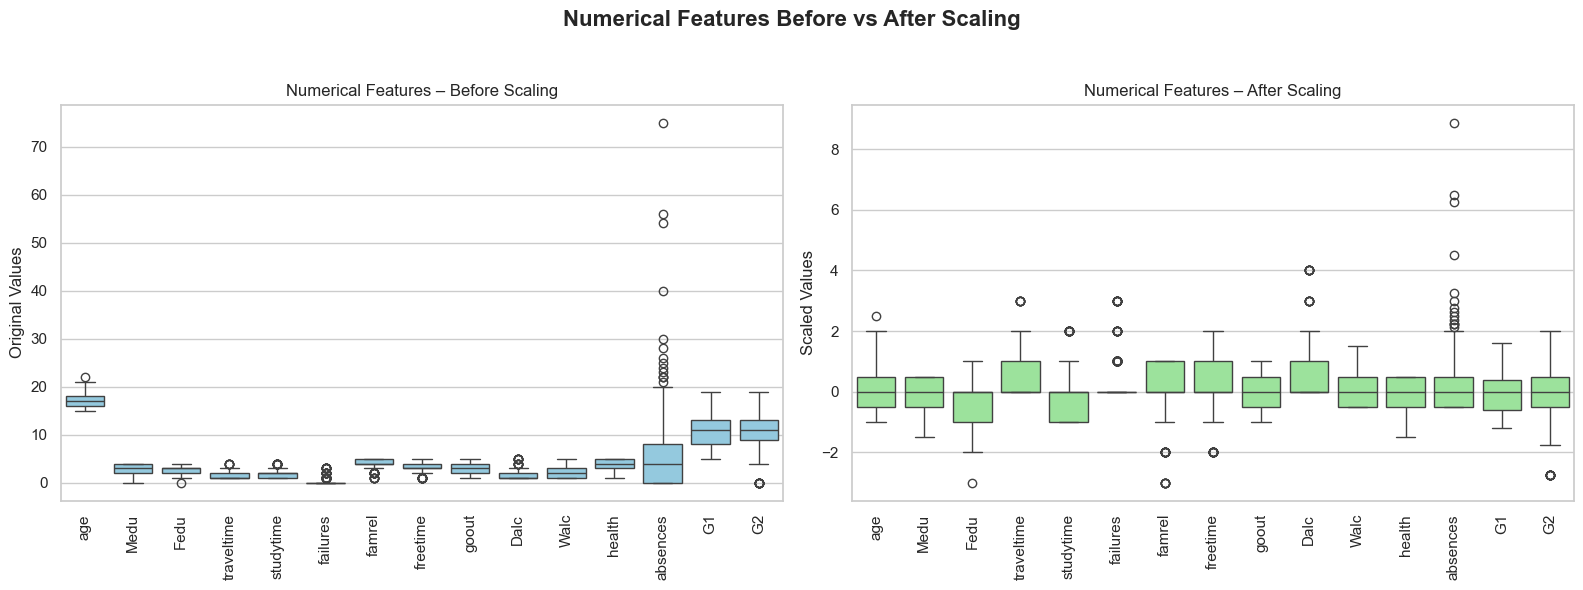

In [102]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Before Scaling
sns.boxplot(
    data=X_train[numerical_cols],
    ax=axes[0],
    color="skyblue"
)

axes[0].set_title("Numerical Features – Before Scaling")
axes[0].set_ylabel("Original Values")
axes[0].tick_params(axis="x", rotation=90)

# After Scaling
sns.boxplot(
    data=X_num_scaled_df[numerical_cols],
    ax=axes[1],
    color="lightgreen"
)

axes[1].set_title("Numerical Features – After Scaling")
axes[1].set_ylabel("Scaled Values")
axes[1].tick_params(axis="x", rotation=90)

plt.suptitle(
    "Numerical Features Before vs After Scaling",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

save_plot("Numerical_Features_Boxplot_Before_After_Scaling.png")

Categorical preprocessing

Create categorical pipeline

In [103]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

Visualize categorical distributions

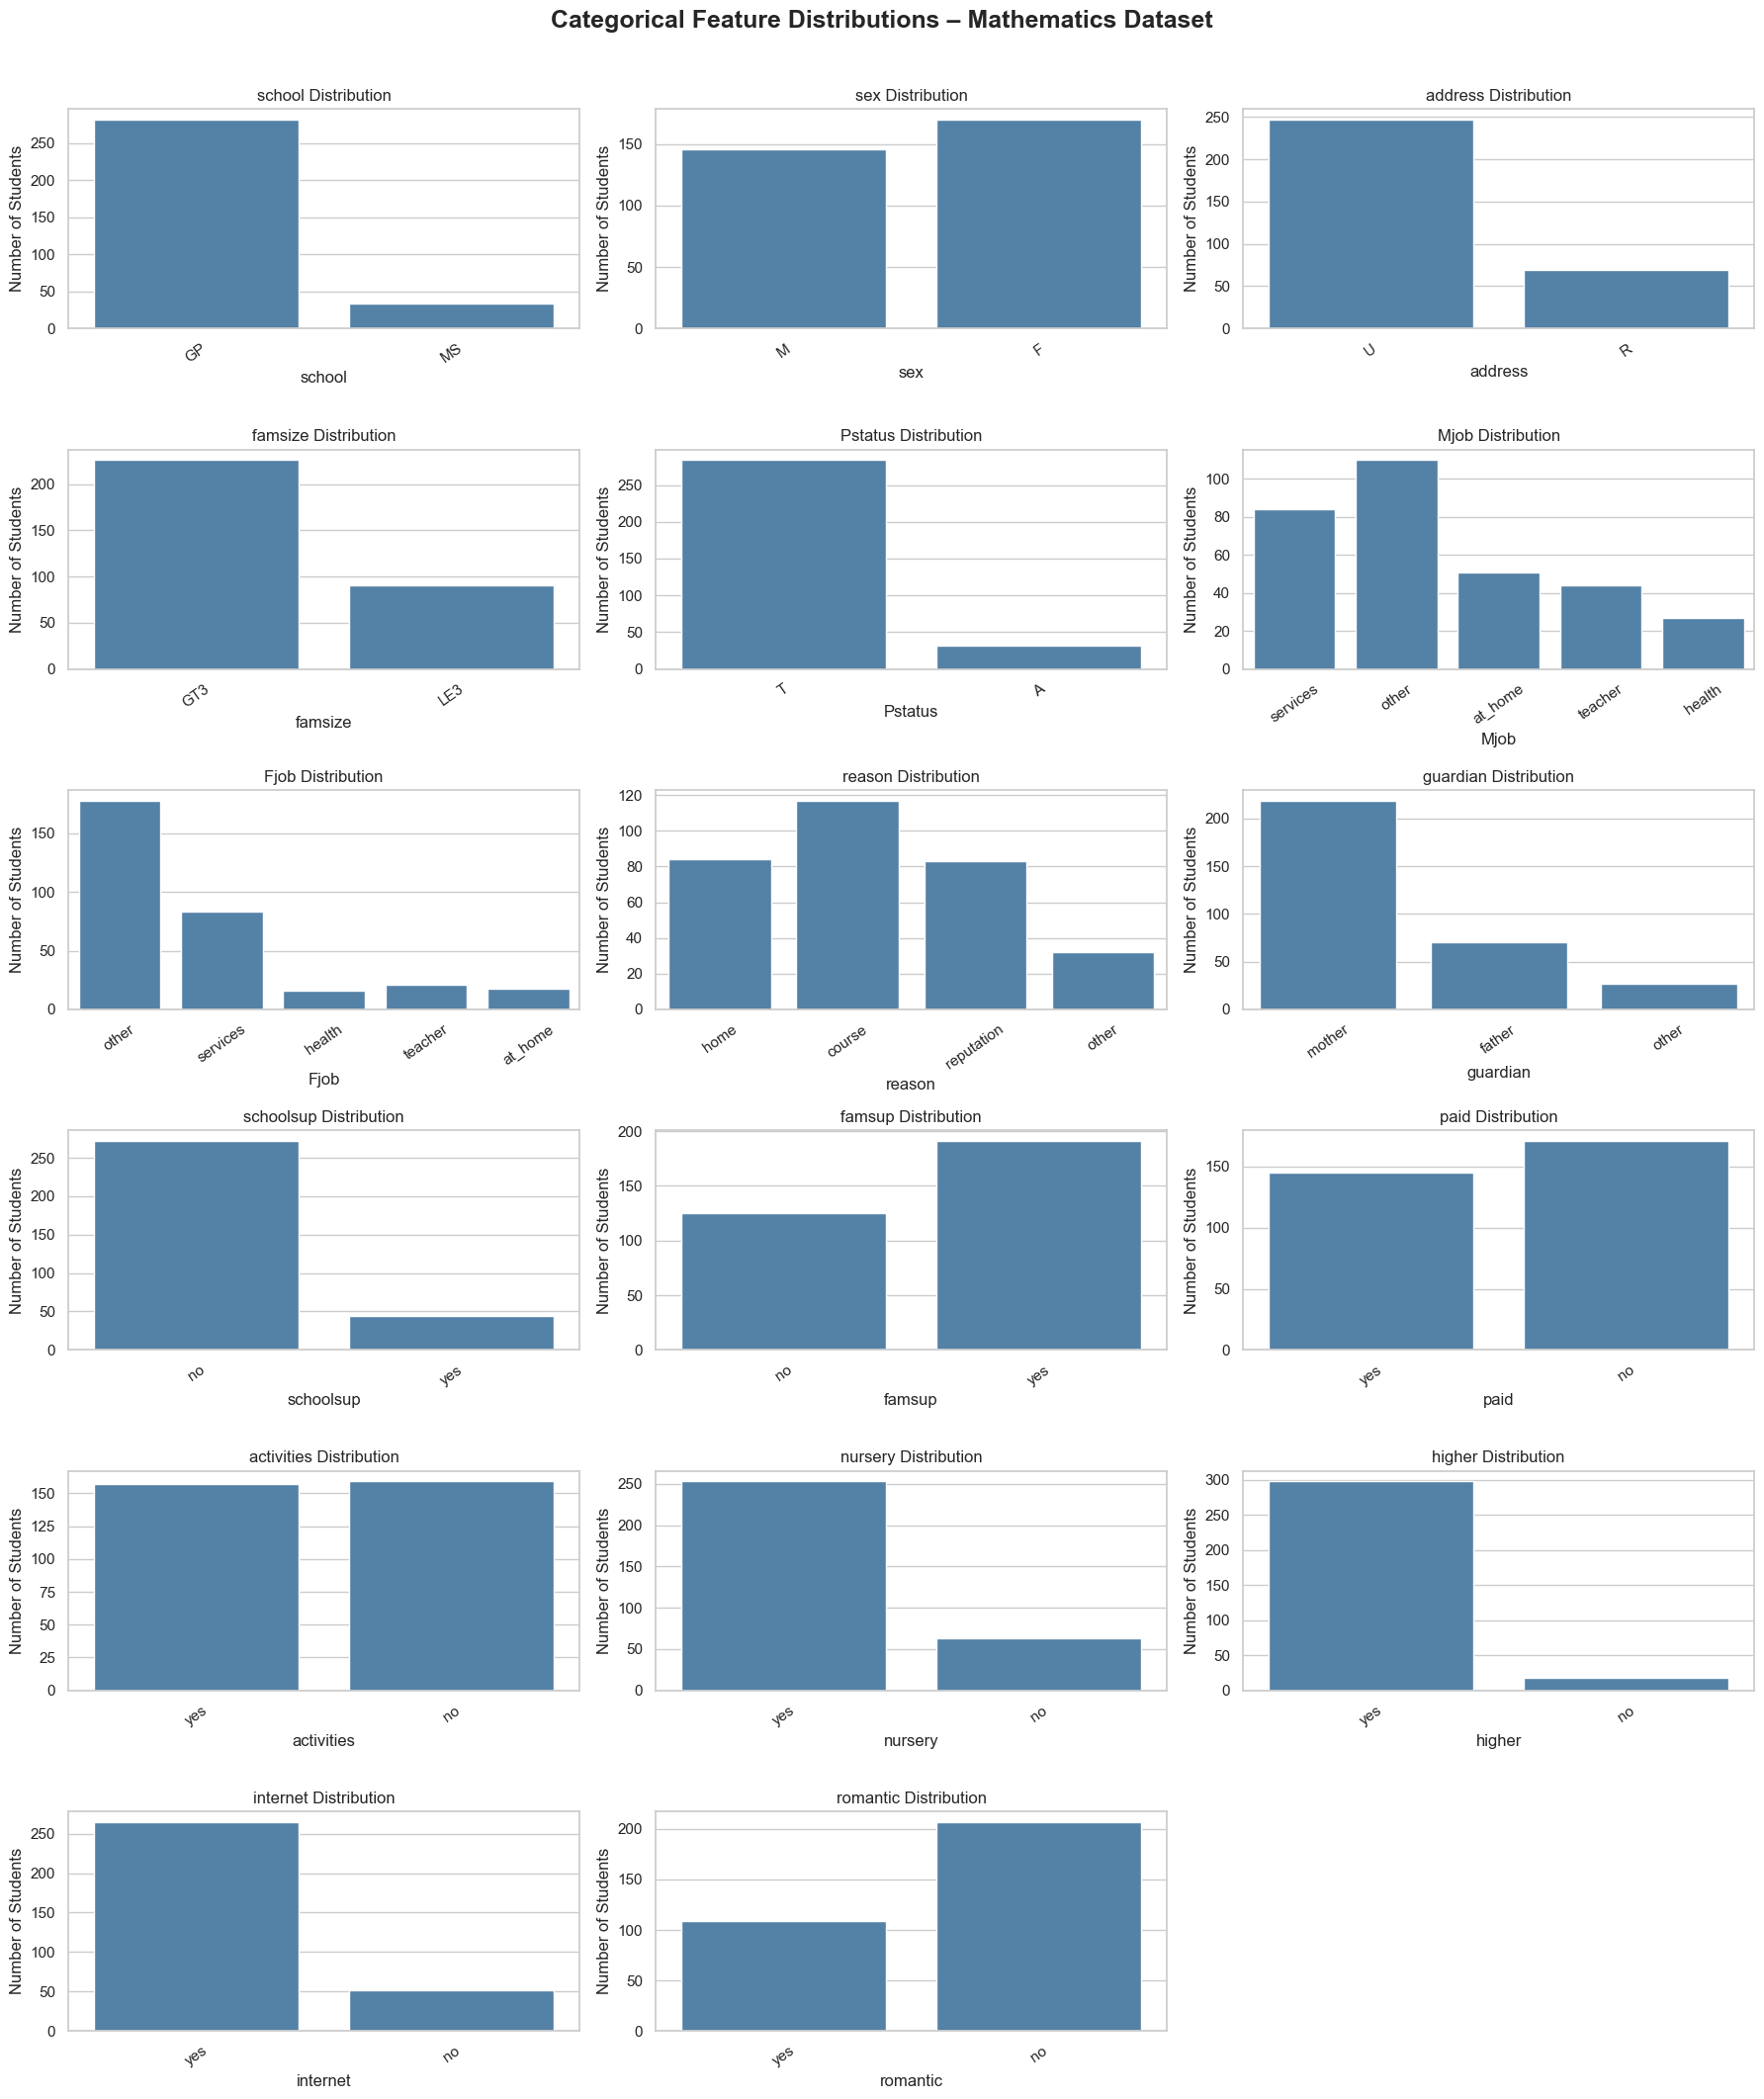

In [104]:
n_cols = 3
n_rows = math.ceil(len(categorical_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, n_rows * 3.5)
)

axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(
        data=X_train,
        x=col,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"{col} Distribution")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Number of Students")
    axes[i].tick_params(axis="x", rotation=35)

for j in range(len(categorical_cols), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Categorical Feature Distributions – Mathematics Dataset",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

save_plot("Categorical_Feature_Distributions.png")

Visualize categorical features vs G3

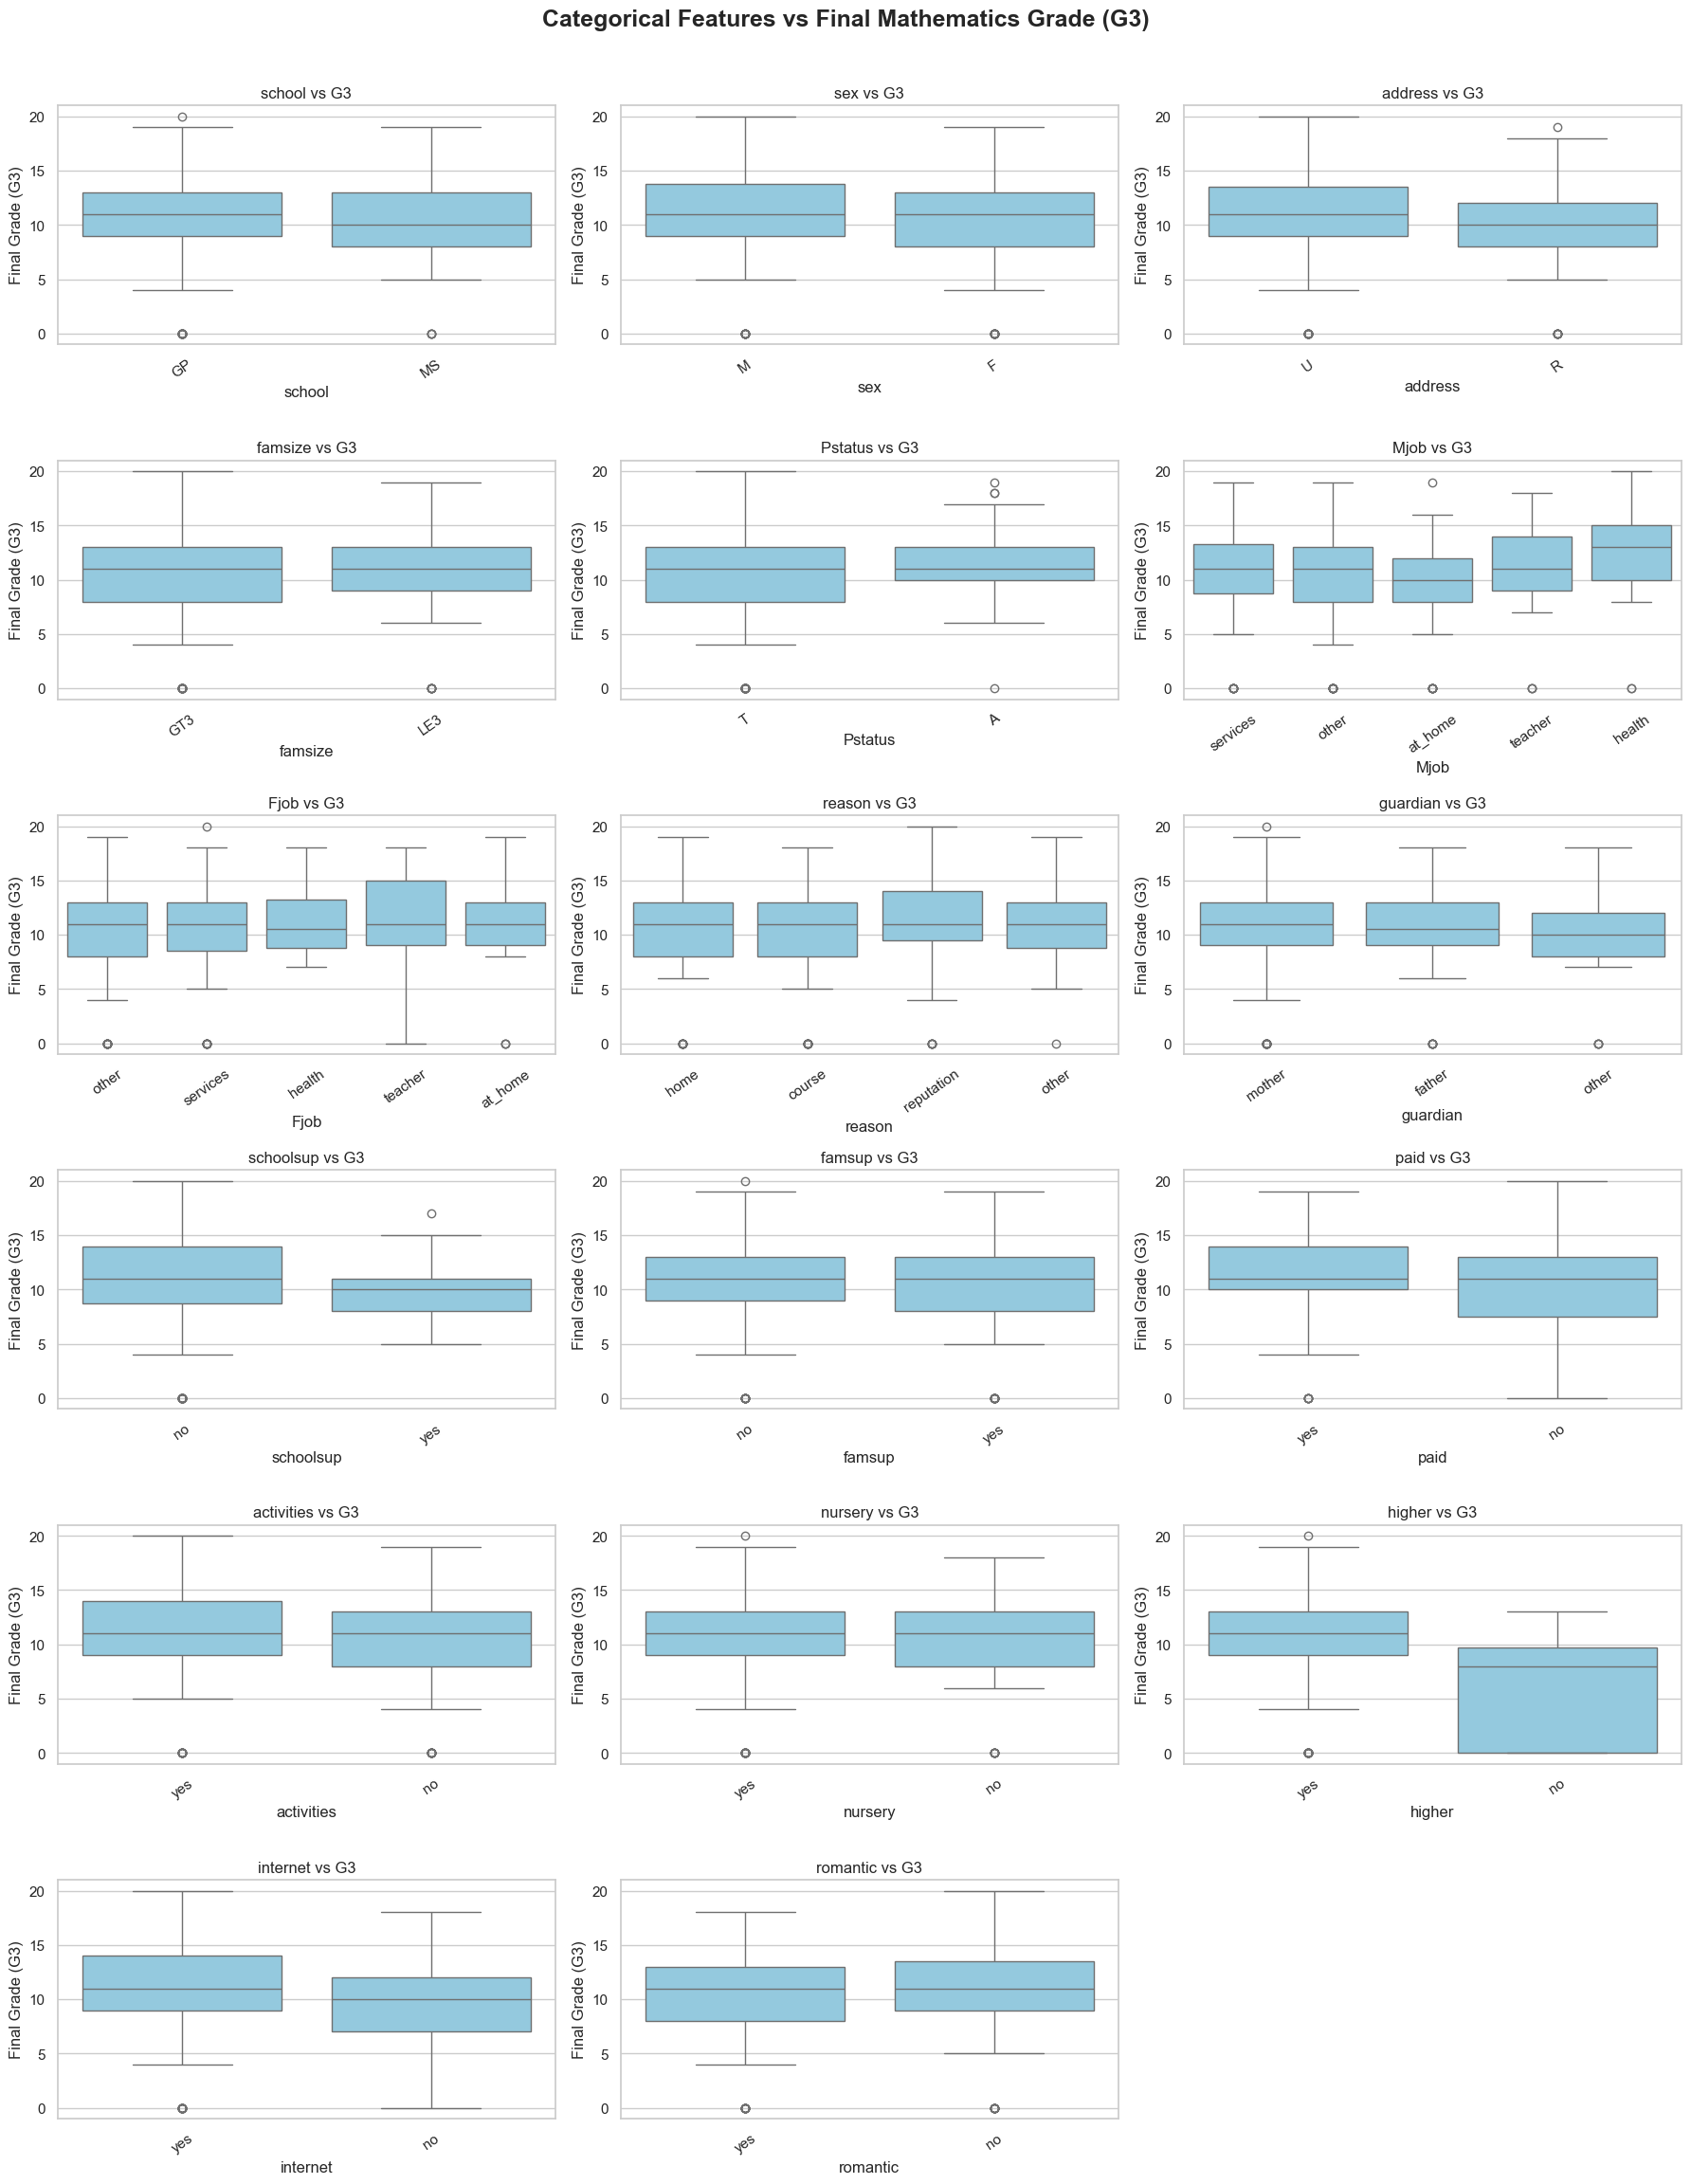

In [105]:
train_data = X_train.copy()
train_data["G3"] = y_train

n_cols = 3
n_rows = math.ceil(len(categorical_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, n_rows * 3.8)
)

axes = axes.flatten()

for i, col in enumerate(categorical_cols):

    sns.boxplot(
        data=train_data,
        x=col,
        y="G3",
        ax=axes[i],
        color="skyblue"
    )

    axes[i].set_title(f"{col} vs G3")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Final Grade (G3)")
    axes[i].tick_params(axis="x", rotation=35)

for j in range(len(categorical_cols), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Categorical Features vs Final Mathematics Grade (G3)",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

save_plot("Categorical_Features_vs_Final_Grade_G3.png")

Fit and visualize One-Hot Encoding

In [106]:
X_cat_encoded = categorical_pipeline.fit_transform(
    X_train[categorical_cols]
)

encoder = categorical_pipeline.named_steps["encoder"]

encoded_columns = encoder.get_feature_names_out(
    categorical_cols
)

X_cat_df = pd.DataFrame(
    X_cat_encoded.toarray()
    if hasattr(X_cat_encoded, "toarray")
    else X_cat_encoded,
    columns=encoded_columns,
    index=X_train.index
)

print("Before encoding:")
display(X_train[categorical_cols].head())

print("After encoding:")
display(X_cat_df.head())

Before encoding:


,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
181,GP,M,U,GT3,T,services,other,home,mother,no,no,yes,yes,yes,yes,yes,yes
194,GP,M,U,GT3,T,other,other,home,father,no,no,no,no,yes,yes,yes,no
173,GP,F,U,GT3,T,at_home,services,home,mother,no,no,no,yes,no,yes,yes,yes
63,GP,F,U,GT3,T,teacher,health,home,mother,yes,yes,yes,yes,yes,yes,yes,no
253,GP,M,R,GT3,T,other,other,course,mother,no,no,no,yes,no,yes,no,no


After encoding:


,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,Pstatus_T,...,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
181,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
194,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
173,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,...,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
63,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
253,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0


One-Hot Encoding heatmap

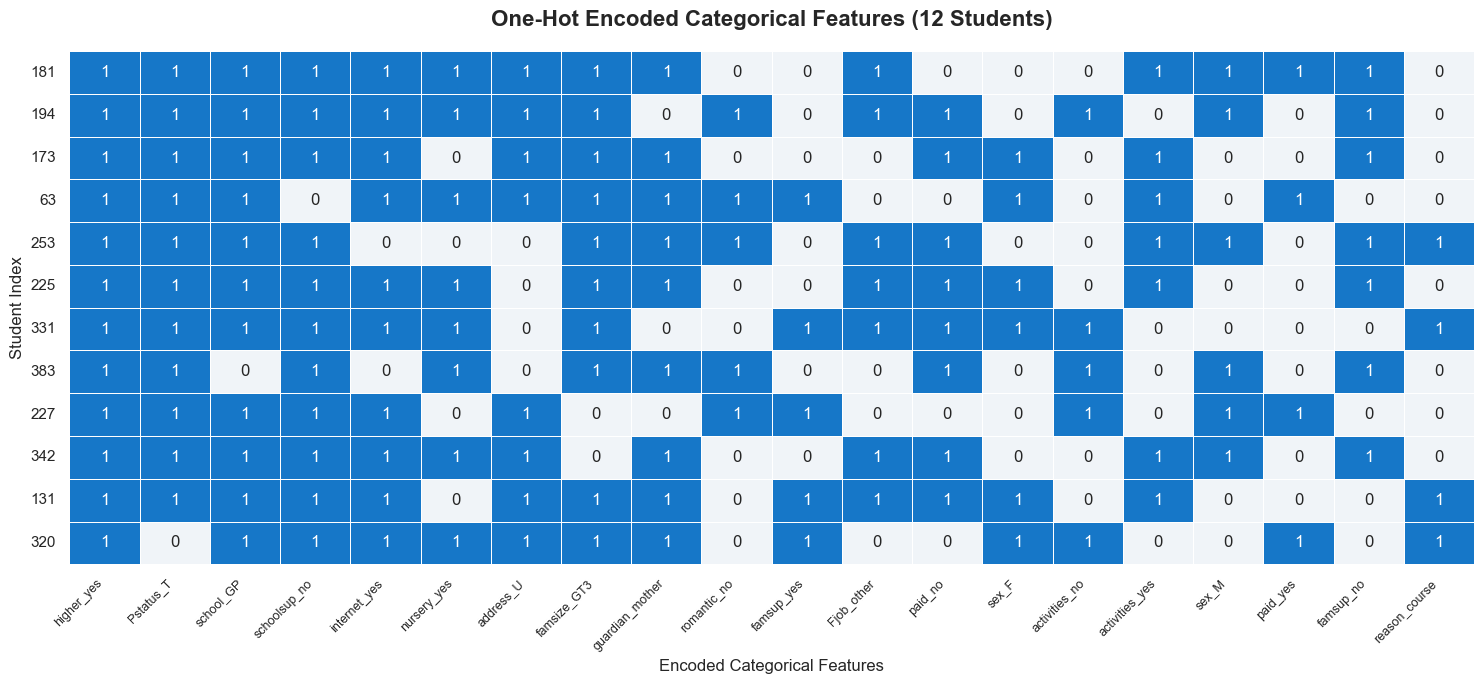

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

output_dir = Path(r"C:\Users\U S E R\Desktop\ML Assigment\project\output")
output_dir.mkdir(parents=True, exist_ok=True)

# Select the most frequently active encoded columns
top_columns = X_cat_df.sum().sort_values(
    ascending=False
).head(20).index

heatmap_data = X_cat_df[top_columns].head(12)

plt.figure(figsize=(15, 7))

sns.heatmap(
    heatmap_data,
    cmap=sns.color_palette(["#F0F4F8", "#1677C8"]),
    linewidths=0.6,
    linecolor="white",
    cbar=False,
    annot=True,
    fmt=".0f"
)

plt.title(
    "One-Hot Encoded Categorical Features (12 Students)",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Encoded Categorical Features", fontsize=12)
plt.ylabel("Student Index", fontsize=12)

plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    output_dir / "step12_onehot_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Combine numerical and categorical pipelines

In [108]:
from sklearn.preprocessing import FunctionTransformer

# Separate absences from other numerical features
other_numerical_cols = [
    col for col in numerical_cols
    if col != "absences"
]

# Apply log transformation only to absences
absences_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one"
    )),
    ("scaler", RobustScaler())
])

# Combine all preprocessing
math_preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, other_numerical_cols),
    ("absences_log", absences_pipeline, ["absences"]),
    ("cat", categorical_pipeline, categorical_cols)
])

display(math_preprocessor)

,transformers,"[('num', ...), ('absences_log', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


Fit and transform the training data

In [109]:
X_train_processed = math_preprocessor.fit_transform(X_train)

X_test_processed = math_preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (316, 32)
Processed training shape: (316, 58)
Original testing shape: (79, 32)
Processed testing shape: (79, 58)


Visualize feature count before and after

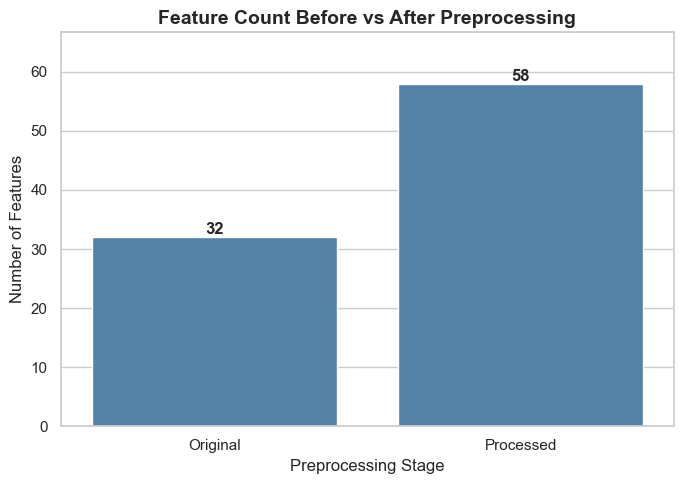

In [110]:
original_count = X_train.shape[1]
processed_count = X_train_processed.shape[1]

plt.figure(figsize=(7, 5))

sns.barplot(
    x=["Original", "Processed"],
    y=[original_count, processed_count],
    color="steelblue"
)

plt.title(
    "Feature Count Before vs After Preprocessing",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Preprocessing Stage")
plt.ylabel("Number of Features")

plt.ylim(0, max(original_count, processed_count) * 1.15)

for i, value in enumerate([original_count, processed_count]):
    plt.text(
        i,
        value + 0.5,
        str(value),
        ha="center",
        fontweight="bold",
        fontsize=12
    )

plt.tight_layout()

save_plot("Feature_Count_Before_After_Preprocessing.png")


Visualize the transformed feature matrix

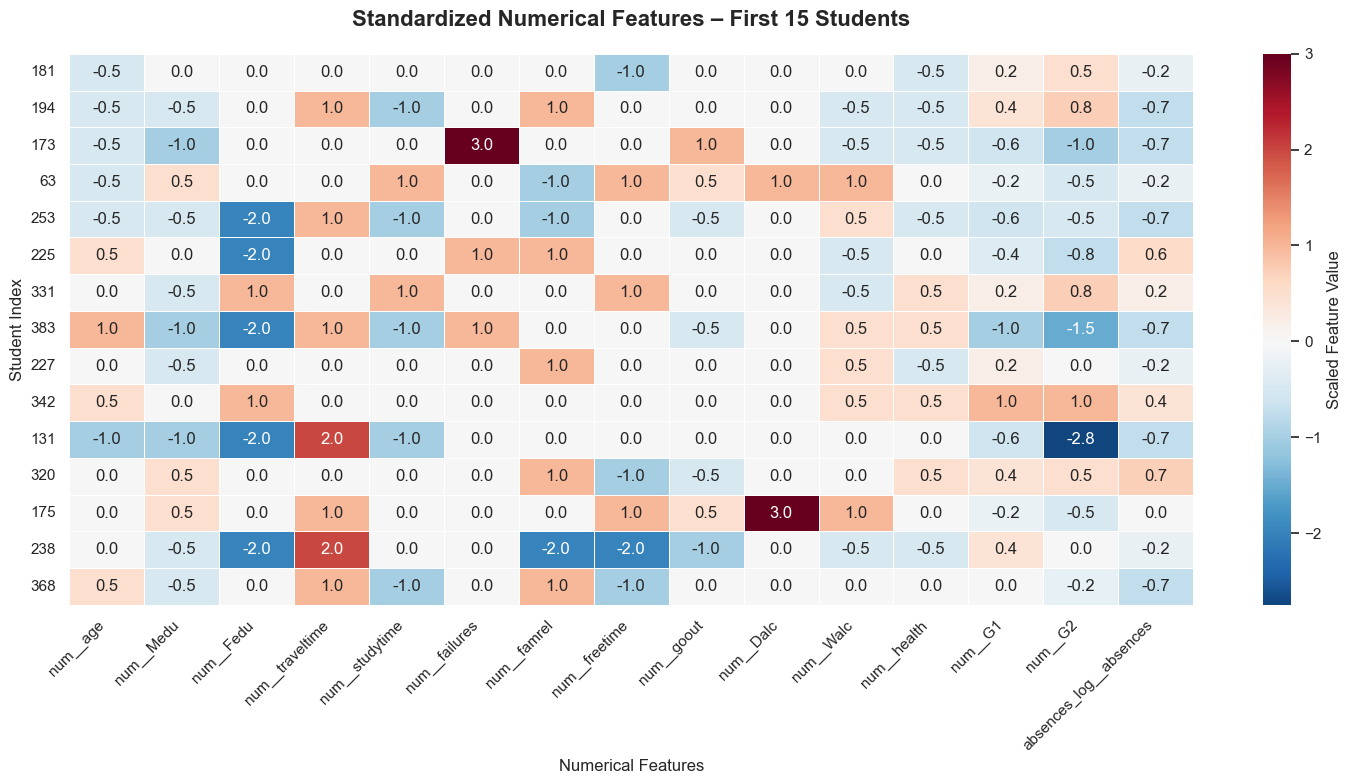

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path

output_dir = Path(
    r"C:\Users\U S E R\Desktop\ML Assigment\project\output"
)

output_dir.mkdir(parents=True, exist_ok=True)

# Get processed feature names
feature_names = math_preprocessor.get_feature_names_out()

# Convert processed data into DataFrame
X_train_clean = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=feature_names,
    index=X_train.index
)

# Select numerical features from ColumnTransformer
numerical_feature_names = [
    col for col in X_train_clean.columns
    if col.startswith(("num__", "absences_log__"))
]

# Select first 15 students
heatmap_data = X_train_clean[
    numerical_feature_names
].head(15)

plt.figure(figsize=(15, 8))

sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Scaled Feature Value"}
)

plt.title(
    "Standardized Numerical Features – First 15 Students",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Numerical Features", fontsize=12)
plt.ylabel("Student Index", fontsize=12)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    output_dir / "step13_numerical_preprocessing_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [112]:
from pathlib import Path
import pandas as pd

processed_dir = Path(
    r"C:\Users\U S E R\Desktop\ML Assigment\project\data\processed"
)

processed_dir.mkdir(parents=True, exist_ok=True)

feature_names = math_preprocessor.get_feature_names_out()

# Training dataset
train_processed_df = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=feature_names,
    index=X_train.index
)

# Testing dataset
test_processed_df = pd.DataFrame(
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed,
    columns=feature_names,
    index=X_test.index
)

# Add target values
train_processed_df["G3"] = y_train
test_processed_df["G3"] = y_test

# Save files
train_processed_df.to_csv(
    processed_dir / "math_train_processed.csv",
    index=False
)

test_processed_df.to_csv(
    processed_dir / "math_test_processed.csv",
    index=False
)

print("Training CSV saved:", processed_dir / "math_train_processed.csv")
print("Testing CSV saved:", processed_dir / "math_test_processed.csv")

Training CSV saved: C:\Users\U S E R\Desktop\ML Assigment\project\data\processed\math_train_processed.csv
Testing CSV saved: C:\Users\U S E R\Desktop\ML Assigment\project\data\processed\math_test_processed.csv


In [113]:
import joblib

models_dir = Path(
    r"C:\Users\U S E R\Desktop\ML Assigment\project\models"
)

models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    math_preprocessor,
    models_dir / "math_preprocessor.joblib"
)

print("Fitted preprocessing pipeline saved.")

Fitted preprocessing pipeline saved.
